In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import seaborn as sns

plt.style.use(["science","bright","grid"])

In [88]:
T_WRITE_LIST = [0.1, 0.2, 0.4, 0.8, 1.6, 3.2, 6.4]
T_WAIT_LIST  = [0.1, 0.2, 0.4, 0.8, 1.2, 1.6, 2.4, 3.2, 4.8, 6.4, 12.8, 25.6]
PATH            = "../../data/raw/dynamic_resistances/set_paired_pulse/"
TAU_0           = 2e-9
data            = {}

for t_write in T_WRITE_LIST:
    data[t_write] = {}
    for t_wait in T_WAIT_LIST:
        try:
            df  = pd.read_csv(f"{PATH}set_tw{t_write:.1f}ns_twait{t_wait:.1f}ns_tau{TAU_0*1e9:.1f}ns.csv")
            df  = df.drop(columns=['E1','G','Eq_Jumps','Jumps'])
            
            df['Total'] = df['Observable'] + df['Displacement']
            df['Resistance'] = pd.read_parquet(f"{PATH}resistances_set_tw{t_write:.1f}ns_twait{t_wait:.1f}ns_tau{TAU_0*1e9:.1f}ns.parquet").mean(axis=1).values
            df['Potential'] = pd.read_parquet(f"{PATH}mean_state_set_tw{t_write:.1f}ns_twait{t_wait:.1f}ns_tau{TAU_0*1e9:.1f}ns.parquet").mean(axis=1).values
            
            data[t_write][t_wait] = df
        except:
            pass

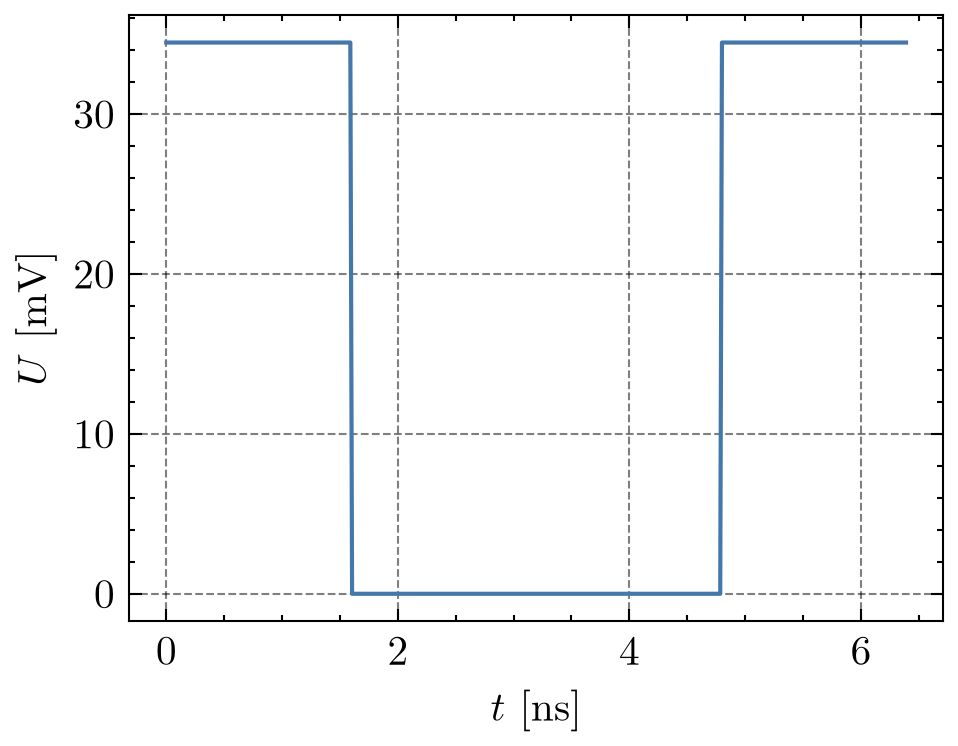

In [146]:
t_write = 1.6
t_wait = 3.2

t = data[t_write][t_wait]['t']*1e9
x = data[t_write][t_wait]['E0']*1000

fig = plt.figure(dpi=300)
ax  = fig.add_subplot()
_   = ax.plot(t, x, 0, alpha=1)
_   = ax.set_xlabel('$t$~[ns]')
_   = ax.set_ylabel('$U$~[mV]')

fig.savefig("plots/set_paired_pulse/two_pulse.svg", transparent=True, bbox_inches='tight')

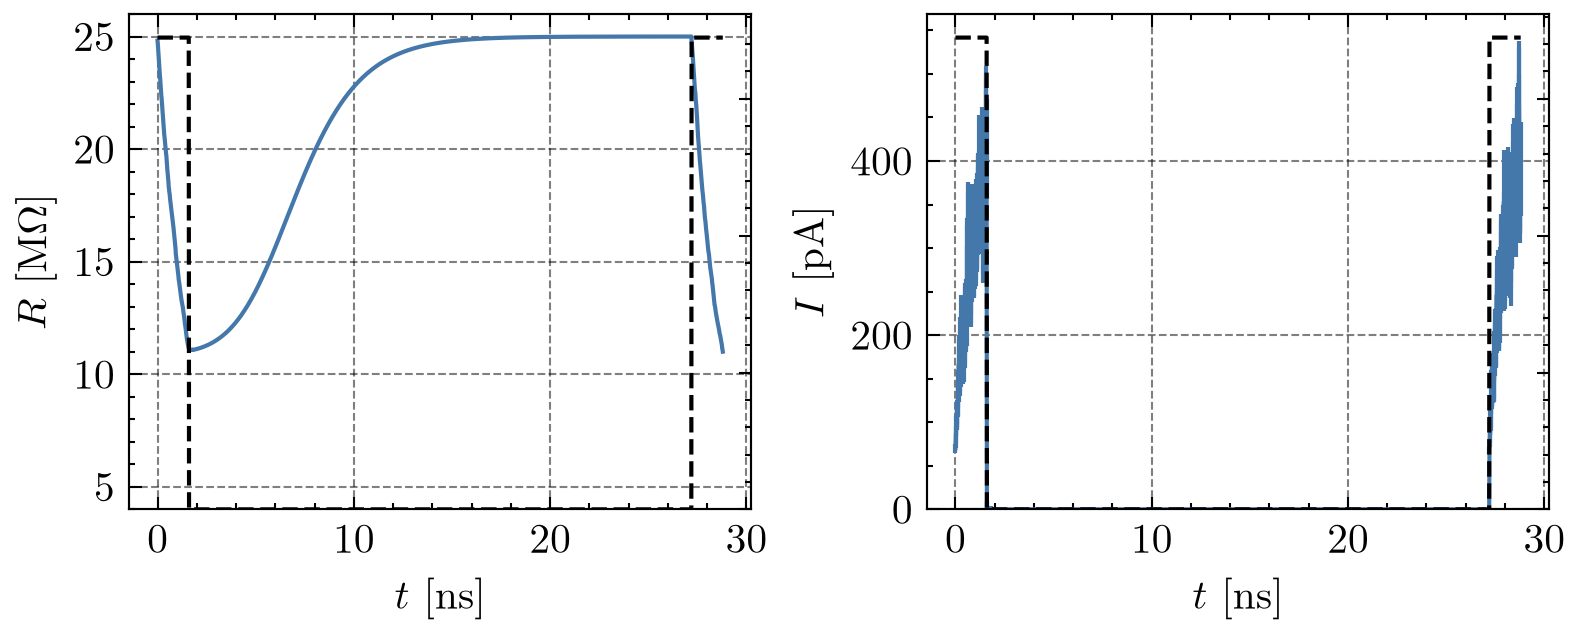

In [150]:
t_write = 1.6
t_wait = 25.6

t = data[t_write][t_wait]['t']*1e9
x = data[t_write][t_wait]['E0']*1000
y_t = data[t_write][t_wait]['Observable']*1e-6
y_e = data[t_write][t_wait]['Error']*1e-6
p = data[t_write][t_wait]['Potential']*1000
r = data[t_write][t_wait]['Resistance']

fig = plt.figure(dpi=300, layout='constrained')
fig.set_figwidth(fig.get_figwidth()*1.5)
fig.set_figheight(fig.get_figheight()*0.8)

ax  = fig.add_subplot(1,2,1)
ax2 = ax.twinx()
_   = ax.errorbar(t, r, 0, alpha=1)
_   = ax2.plot(t, x, color='black', ls='--')
_   = ax.set_xlabel('$t$~[ns]')
_   = ax.set_ylabel('$R$~[M$\\Omega$]')
_   = ax.set_ylim(4, 26)
_   = ax2.set_ylim(0)
_   = ax2.grid(False)
_   = ax2.set_yticklabels("")

ax  = fig.add_subplot(1,2,2)
ax2 = ax.twinx()
_   = ax.errorbar(t, y_t, y_e, alpha=1)
_   = ax2.plot(t, x, color='black', ls='--')
_   = ax.set_xlabel('$t$~[ns]')
_   = ax.set_ylabel('$I$~[pA]')
_   = ax.set_ylim(0)
_   = ax2.set_ylim(0)
_   = ax2.grid(False)
_   = ax2.set_yticklabels("")

fig.savefig(f"plots/set_paired_pulse/response_write_{t_write:.1f}_wait_{t_wait:.1f}.svg", transparent=True, bbox_inches='tight')

In [115]:
ppf_array = np.zeros(shape=(len(T_WRITE_LIST),len(T_WAIT_LIST)))
for i, t_write in enumerate(T_WRITE_LIST):
    for j, t_wait in enumerate(T_WAIT_LIST):
        x   = data[t_write][t_wait]['E0'].values
        ii  = np.where(x==0)[0]
        i1  = ii[0]
        i2  = ii[-1]
        y   = data[t_write][t_wait]['Observable'].values
        y1  = y[:i1]
        y2  = y[i2+1:]
        ppf = (np.mean(y2) - np.mean(y1)) / np.mean(y1)

        ppf_array[i,j] = ppf

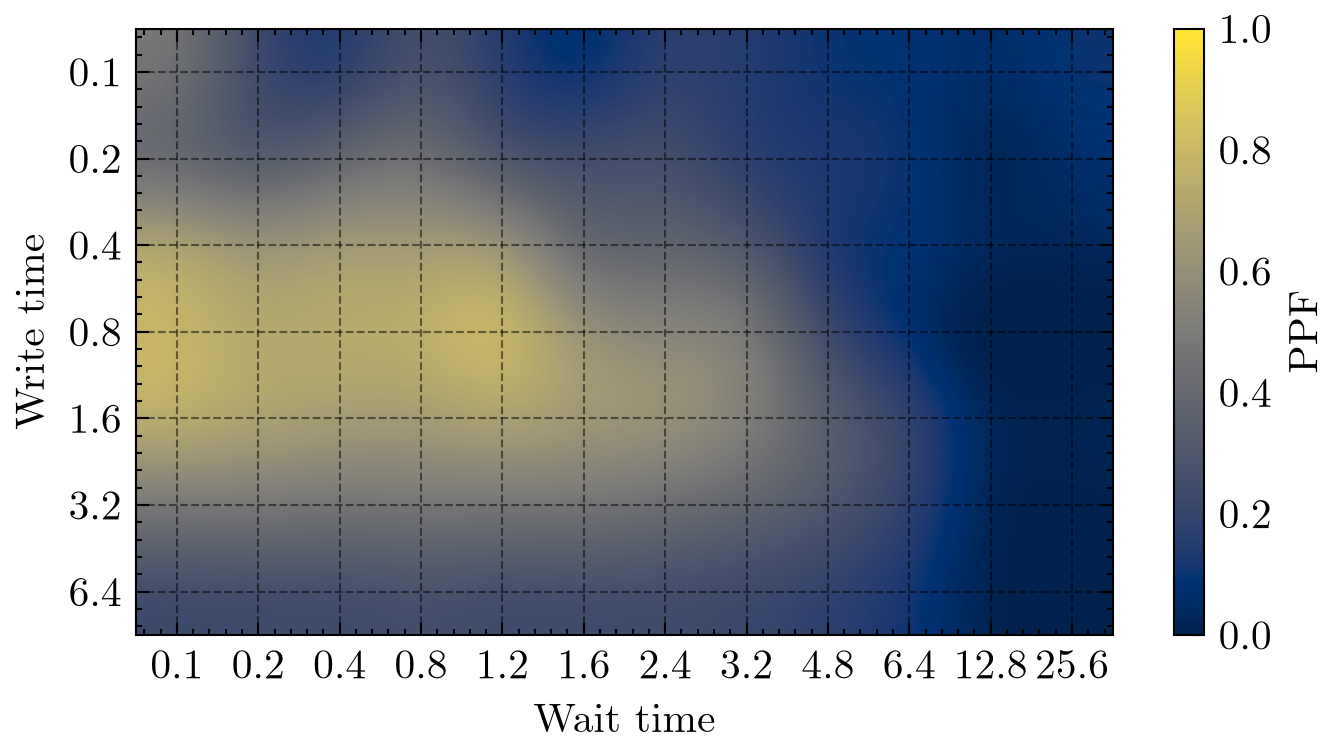

In [149]:
fig, ax = plt.subplots(dpi=300)
_       = fig.set_figwidth(fig.get_figwidth()*1.5)

im = ax.imshow(ppf_array,vmin=0,vmax=1,cmap='cividis',origin='upper',aspect='auto', interpolation='bicubic')

# Set ticks at the center of each cell
ax.set_xticks(np.arange(len(T_WAIT_LIST)))
ax.set_yticks(np.arange(len(T_WRITE_LIST)))

# Set tick labels
ax.set_xticklabels(T_WAIT_LIST)
ax.set_yticklabels(T_WRITE_LIST)

# Axis labels
ax.set_xlabel('Wait time')
ax.set_ylabel('Write time')

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('PPF')

fig.savefig(f"plots/set_paired_pulse/ppf_heatmap.svg", transparent=True, bbox_inches='tight')